# Cleaning, Preprocessing & Image EDA: Traditional African Drums

**P2 Notebook 2**

Notebook 1 left us a folder of search results for each of eight drum types. That is not yet a dataset: it holds wrong subjects, duplicate images, and photos of every shape and size. This notebook turns it into a clean, model-ready dataset, documents what that dataset looks like, and splits it for modeling.

## Learning objectives

- Account for every image that was removed during cleaning, so that no count is left unexplained
- Check for duplicate images, including the same image saved under two different classes, before they can leak across a train/test split
- Describe an image dataset with a sample grid, dimension and aspect-ratio distributions, per-class mean images and class counts
- Choose and defend a color mode and a resize strategy for the subject at hand
- Split with stratification and export arrays that Notebooks 3 and 4 and the Streamlit app can load without guessing

## Background

Cleaning images is done by hand. There is no reliable automated way to tell that a search for "bata drum" returned a pair of shoes, so we removed those images ourselves by looking at them. What this notebook does is check and record the result: it counts what is left, verifies that no duplicates remain, and refuses to continue if a class has fewer than 200 images.

## This notebook covers

1. Loading the manifest and the image folders
2. Cleaning summary: what was removed, a duplicate audit, and what was kept
3. Image EDA: sample grid, dimensions and aspect ratios, class support
4. Preprocessing decisions: color mode, resize strategy, per-class mean images
5. Split and export

**Prerequisites:** Notebook 1 (`data/P2_manifest.csv` and the class image folders) and the by-hand cleaning described below.

**Dataset:** our scraped drum images, kept in a local folder outside the repo.

**Produces:** train and test arrays, the label-to-index mapping and the split table in a local folder outside the repo, and the `kept` and `split` columns added to `data/P2_manifest.csv`.

**References:** <https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html>

### Before running anything below: clean the folders by hand

1. Open `MSDS565_data/P2_images/` in your file browser, one class folder at a time, with the view set to large icons.
2. Delete wrong subjects: drawings, memes, product collages, pictures of the *word*, other objects (shoes for `bata`), people with no drum visible, and photos where several kinds of drum are the main subject.
3. Delete duplicates you spot, including an image that appears in two different class folders.
4. Do not rename files. The manifest finds each image by its name.

Do not re-run Notebook 1's scrape cell once you start cleaning, because it deletes and rebuilds a class's folder.

In [1]:
import json
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import train_test_split

pd.set_option('display.max_columns',100)
pd.set_option('display.max_rows',100)

plt.style.use('dark_background')

import warnings
warnings.filterwarnings('ignore')

# Where Notebook 1 left things. The images live outside the repo; only the manifest is in it.
IMAGE_DIR = Path.home() / 'MSDS565_data' / 'P2_images'
MANIFEST_PATH = Path('..') / 'data' / 'P2_manifest.csv'

# Where this notebook writes the model-ready arrays, also outside the repo
OUT_DIR = Path.home() / 'MSDS565_data' / 'P2_processed'
OUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42             # the assignment fixes random_state=42 for the split
IMG_SIZE = 224        # models take 224 x 224 input
MIN_PER_CLASS = 200   # the assignment's floor on usable images per class

## 1. Loading the manifest and the image folders

We start from the two things Notebook 1 left behind and carry nothing over from its session: the manifest, which lists every image the scraper saved, and the class folders on disk. The manifest says what was downloaded; the folders say what is *still there* after cleaning. The difference between them is the by-hand cleaning.

Two columns from Notebook 1 matter here. `readable` is `False` for files that failed to open and were deleted. If a `kept` or `split` column is already in the manifest from an earlier run of this notebook, we drop it: both are recomputed from the folders below, so re-running gives the same answer.

In [2]:
manifest = pd.read_csv(MANIFEST_PATH)
manifest = manifest.drop(columns=['kept', 'drop_reason', 'split'], errors='ignore')   # recomputed below

labels = sorted(manifest['label'].unique())
manifest['path'] = [IMAGE_DIR / label / name for label, name in zip(manifest['label'], manifest['filename'])]
manifest['on_disk'] = manifest['path'].map(Path.exists)

# Any image on disk that the manifest does not know about would silently be ignored, so look for them
on_disk_files = {(p.parent.name, p.name) for p in IMAGE_DIR.glob('*/*.jpg')}
manifest_files = set(zip(manifest['label'], manifest['filename']))
stray = sorted(on_disk_files - manifest_files)

print(f'{len(labels)} classes, {len(manifest)} images in the manifest, {int(manifest["on_disk"].sum())} still on disk')
print(f'{len(stray)} files in the folders that are not in the manifest' + ('' if not stray else f', for example {stray[:3]}'))

8 classes, 2782 images in the manifest, 2782 still on disk
0 files in the folders that are not in the manifest


## 2. Cleaning summary

Cleaning happened in two places: by hand in the folders (before this notebook), and in code below, where we audit for duplicates. We account for every image by giving each manifest row exactly one fate:

| Fate | Meaning |
|---|---|
| `unreadable` | Notebook 1's integrity check could not open it and deleted it |
| `removed_by_hand` | Deleted from the folder during our manual cleaning |
| `duplicate` | A copy of another image in the same class; the first copy is kept |
| `duplicate_cross_class` | The same image appears under two different classes; **all** copies are dropped, because its label is ambiguous |
| (kept) | Survived everything, and goes into the dataset |

### 2.1 What the by-hand cleaning removed

An image counts as removed by hand when the manifest says it was readable but the file is no longer in its folder.

In [3]:
manifest['drop_reason'] = None
manifest.loc[~manifest['readable'], 'drop_reason'] = 'unreadable'
manifest.loc[manifest['readable'] & ~manifest['on_disk'], 'drop_reason'] = 'removed_by_hand'

hand = (manifest.groupby('label')['drop_reason']
        .apply(lambda s: int((s == 'removed_by_hand').sum()))
        .rename('removed_by_hand'))
hand

label
ashiko          0
bata            0
bendir          0
bougarabou      0
djembe          0
dunun           0
sabar           0
talking_drum    0
Name: removed_by_hand, dtype: int64

### 2.2 Duplicate audit

Overlapping queries return the same image more than once, sometimes under two different classes, and the scraper only removes exact repeats of the same URL. Duplicates matter for more than tidiness: if one copy of an image lands in the training set and another in the test set, the model is tested on something it has already seen and the accuracy is fiction.

We checked for duplicates by eye while cleaning, and here we verify. Each remaining image gets a **difference hash** (dHash): the image is shrunk to a 9 × 8 grayscale grid and each pixel is compared with its right-hand neighbor, giving 64 yes/no values that describe the picture's overall light-and-dark pattern. The same photo saved at a different size or compression ends up with almost the same 64 values, while different photos differ in many more of them.

Two images are called duplicates only when they pass **two tests**:

1. **Their hashes differ in at most 4 of the 64 values.** That catches the same image at a different size or JPEG quality.
2. **Shrunk to 32 × 32 grayscale, at most 2% of their pixels differ by more than 12 gray levels (out of 255).** A hash alone is not enough: two product shots of *different* drums, each centered on a plain white background, contribute the same 'flat background' values to the hash and can look almost identical to it. Their pixels, though, differ across the whole area where the drums are, and this second test sees that. A true copy that was only resized or re-saved differs just along sharp edges, which is a small fraction of the picture. (We count *how many* pixels differ rather than averaging the difference, because an average is diluted by a large plain background.)

Both limits are deliberately strict. The cost is that an edited or cropped copy of an image can slip through; the cost of loose limits would be throwing away genuinely different photos, and that damages the classes we are most worried about running short. The spot check after the audit lets us confirm that what was flagged really is the same image.

What happens to a flagged group depends on its labels:
- **All in one class:** keep the first copy (by filename) and drop the rest.
- **Spanning two or more classes:** drop every copy. We cannot know which label is right, and keeping one would teach the model a coin flip.

Files are never deleted here, only excluded from the dataset, so the audit can be re-run with a different threshold.

This step also reads each remaining image once to record its original width, height and color mode, which the EDA below uses.

In [4]:
DUP_THRESHOLD = 4   # max differing bits (of 64) in the hash for two images to count as the same picture
DUP_PIXEL_TOL = 12      # a thumbnail pixel counts as different if it differs by more than this many gray levels (of 255)
DUP_PIXEL_FRAC = 0.02   # and at most this fraction of the 32 x 32 thumbnail's pixels may differ


def dhash(img, size=8):
    # 9 x 8 grayscale grid; each pixel compared with its right-hand neighbor gives 64 bits
    small = np.asarray(img.convert('L').resize((size + 1, size), Image.Resampling.LANCZOS), dtype=np.int16)
    return (small[:, 1:] > small[:, :-1]).flatten()


info, hashes, thumbs = {}, {}, {}
for idx in manifest.index[manifest['drop_reason'].isna()]:
    try:
        with Image.open(manifest.at[idx, 'path']) as img:
            img.load()
            info[idx] = (img.size[0], img.size[1], img.mode)
            hashes[idx] = dhash(img)
            thumbs[idx] = np.asarray(img.convert('L').resize((32, 32), Image.Resampling.LANCZOS), dtype=np.float32)
    except Exception:
        manifest.at[idx, 'drop_reason'] = 'unreadable'     # damaged since Notebook 1

manifest['orig_w'] = pd.Series({i: v[0] for i, v in info.items()})
manifest['orig_h'] = pd.Series({i: v[1] for i, v in info.items()})
manifest['mode'] = pd.Series({i: v[2] for i, v in info.items()})

# Hamming distance between every pair of remaining images
alive = [i for i in manifest.index if i in hashes]
H = np.stack([hashes[i] for i in alive]).astype(np.float32)
dist = H @ (1 - H).T + (1 - H) @ H.T

# Group images that are (transitively) within the threshold of each other
parent = list(range(len(alive)))
def find(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]
        a = parent[a]
    return a
rows_, cols_ = np.where(np.triu(dist <= DUP_THRESHOLD, k=1))
for a, b in zip(rows_, cols_):
    if (np.abs(thumbs[alive[a]] - thumbs[alive[b]]) > DUP_PIXEL_TOL).mean() <= DUP_PIXEL_FRAC:     # second test: pixels must agree too
        parent[find(a)] = find(b)

groups = {}
for pos in range(len(alive)):
    groups.setdefault(find(pos), []).append(alive[pos])
groups = [sorted(g, key=lambda i: manifest.at[i, 'filename']) for g in groups.values() if len(g) > 1]

examples = []   # (kept or first image, excluded image, note) for the spot check
for group in groups:
    classes_in_group = {manifest.at[i, 'label'] for i in group}
    if len(classes_in_group) > 1:
        for i in group:
            manifest.at[i, 'drop_reason'] = 'duplicate_cross_class'
        examples.append((group[0], group[1], f'in two classes: {manifest.at[group[0], "label"]} / {manifest.at[group[1], "label"]}'))
    else:
        for i in group[1:]:
            manifest.at[i, 'drop_reason'] = 'duplicate'
        examples.append((group[0], group[1], f'same class: {manifest.at[group[0], "label"]}'))

print(f'{len(groups)} groups of duplicate images found among {len(alive)} images '
      f'({int((manifest["drop_reason"] == "duplicate").sum())} copies dropped, '
      f'{int((manifest["drop_reason"] == "duplicate_cross_class").sum())} images dropped for appearing under two classes)')

364 groups of duplicate images found among 2782 images (391 copies dropped, 148 images dropped for appearing under two classes)


**Spot check.** Up to four flagged pairs are shown, left image first. If a pair is not actually the same picture, the threshold is too loose; if you know of duplicates that are not listed, it is too tight. Both are a one-line change to `DUP_THRESHOLD`, `DUP_PIXEL_TOL` or `DUP_PIXEL_FRAC` above.

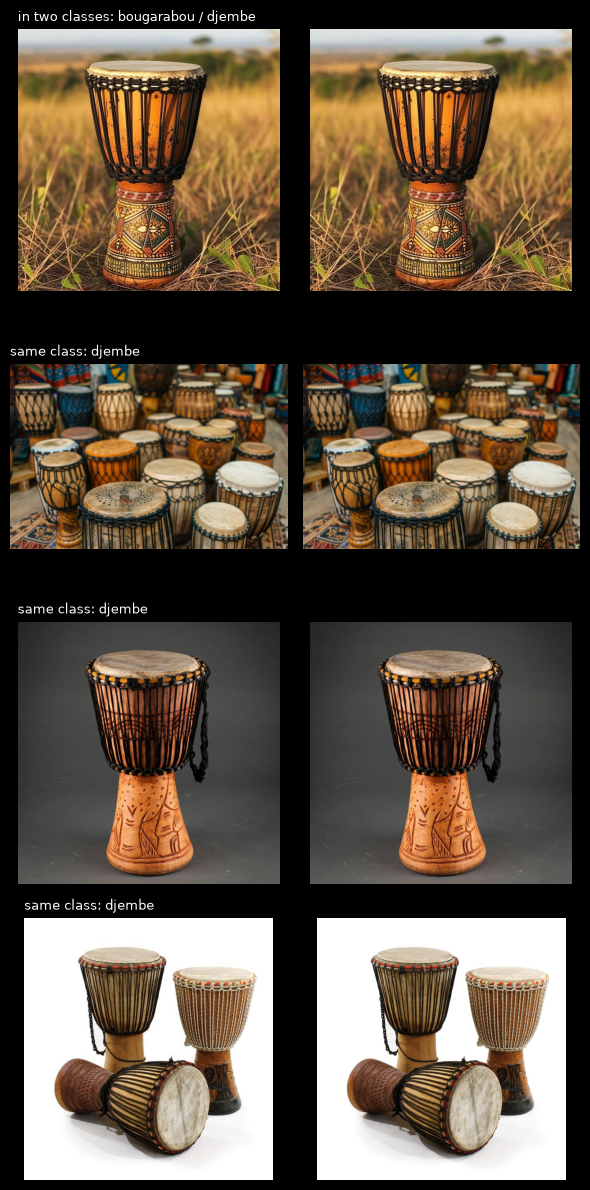

In [5]:
if not examples:
    print('No duplicate groups to show')
else:
    shown = examples[:4]
    fig, axes = plt.subplots(len(shown), 2, figsize=(6, 3 * len(shown)))
    axes = np.atleast_2d(axes)
    for row, (first, second, note) in enumerate(shown):
        for col, idx in enumerate((first, second)):
            axes[row, col].imshow(Image.open(manifest.at[idx, 'path']))
            axes[row, col].axis('off')
        axes[row, 0].set_title(note, loc='left', fontsize=9)
    plt.tight_layout()
    plt.show()

### 2.3 What was kept

One row per class: every image the scraper saved, what happened to each, and what is left. The cell ends with a hard check that every class clears the assignment's 200-image minimum, so a class that falls short stops the notebook here instead of surfacing as a weak result in Notebook 3. If it does, go back to Notebook 1, scrape more for that class, clean again, and re-run from the top.

In [6]:
manifest['kept'] = manifest['drop_reason'].isna()

fates = ['unreadable', 'removed_by_hand', 'duplicate', 'duplicate_cross_class', 'kept']
summary = (pd.crosstab(manifest['label'], manifest['drop_reason'].fillna('kept'))
           .reindex(columns=fates, fill_value=0))
summary.insert(0, 'downloaded', manifest.groupby('label').size())
summary['clears_200'] = summary['kept'] >= MIN_PER_CLASS
summary.loc['TOTAL'] = list(summary.drop(columns='clears_200').sum()) + [bool(summary['clears_200'].all())]

display(summary)      # shown before the check below, so a failing class can be seen

short = summary.index[(summary['clears_200'] == False) & (summary.index != 'TOTAL')].tolist()
assert not short, (f'Classes below {MIN_PER_CLASS} images after cleaning: ' +
                   ', '.join(f"{c} ({int(summary.at[c, 'kept'])}, needs {MIN_PER_CLASS - int(summary.at[c, 'kept'])} more)" for c in short) +
                   '. Scrape more in Notebook 1, clean, and re-run.')
assert summary.loc['TOTAL', 'downloaded'] == len(manifest)      # every image has exactly one fate

kept_df = manifest[manifest['kept']].reset_index(drop=True)
kept_df[['orig_w', 'orig_h']] = kept_df[['orig_w', 'orig_h']].astype(int)

drop_reason,downloaded,unreadable,removed_by_hand,duplicate,duplicate_cross_class,kept,clears_200
label,,,,,,,
ashiko,332,0,0,54,5,273,True
bata,350,0,0,66,31,253,True
bendir,350,0,0,47,0,303,True
bougarabou,350,0,0,80,17,253,True
djembe,350,0,0,36,13,301,True
dunun,350,0,0,42,24,284,True
sabar,350,0,0,27,11,312,True
talking_drum,350,0,0,39,47,264,True
TOTAL,2782,0,0,391,148,2243,True


### 2.4 What we removed

**Duplicates.** The audit in 2.2 found 364 groups of duplicate images among the 2,782 downloaded. It dropped 391 extra copies from within a single class and another 148 images that appeared under two different classes (all copies dropped, because we cannot know which label is right). That is 539 images removed, leaving 2,243. We have not yet removed any images by hand, so the table above shows 0 in removed_by_hand, and every drop so far is from the audit.

**Which classes lost the most.** bata and bougarabou each lost 97 images, followed by talking_drum (86) and dunun (66). bougarabou lost mostly same-class repeats (80 of 97), so its three queries returned many of the same photos. talking_drum lost the most cross-class images (47 of 86). We think this is because its query 'Yoruba dundun talking drum' overlaps with the dunun and bata classes, but we have not checked this. bendir had no cross-class duplicates at all.

**Does every class clear 200?** Yes. The smallest classes are bata and bougarabou (253 each) and talking_drum (264). These margins are small enough that hand cleaning could push them close to 200, so we will recheck the counts after it.

## 3. Image EDA

Everything in this section describes the images as they were scraped, before any resizing, so it shows what the dataset really looks like.

### 3.1 Sample grid

Eight randomly chosen images per class. The sample is random on purpose; the first images in a folder come from whichever query happened to return first.

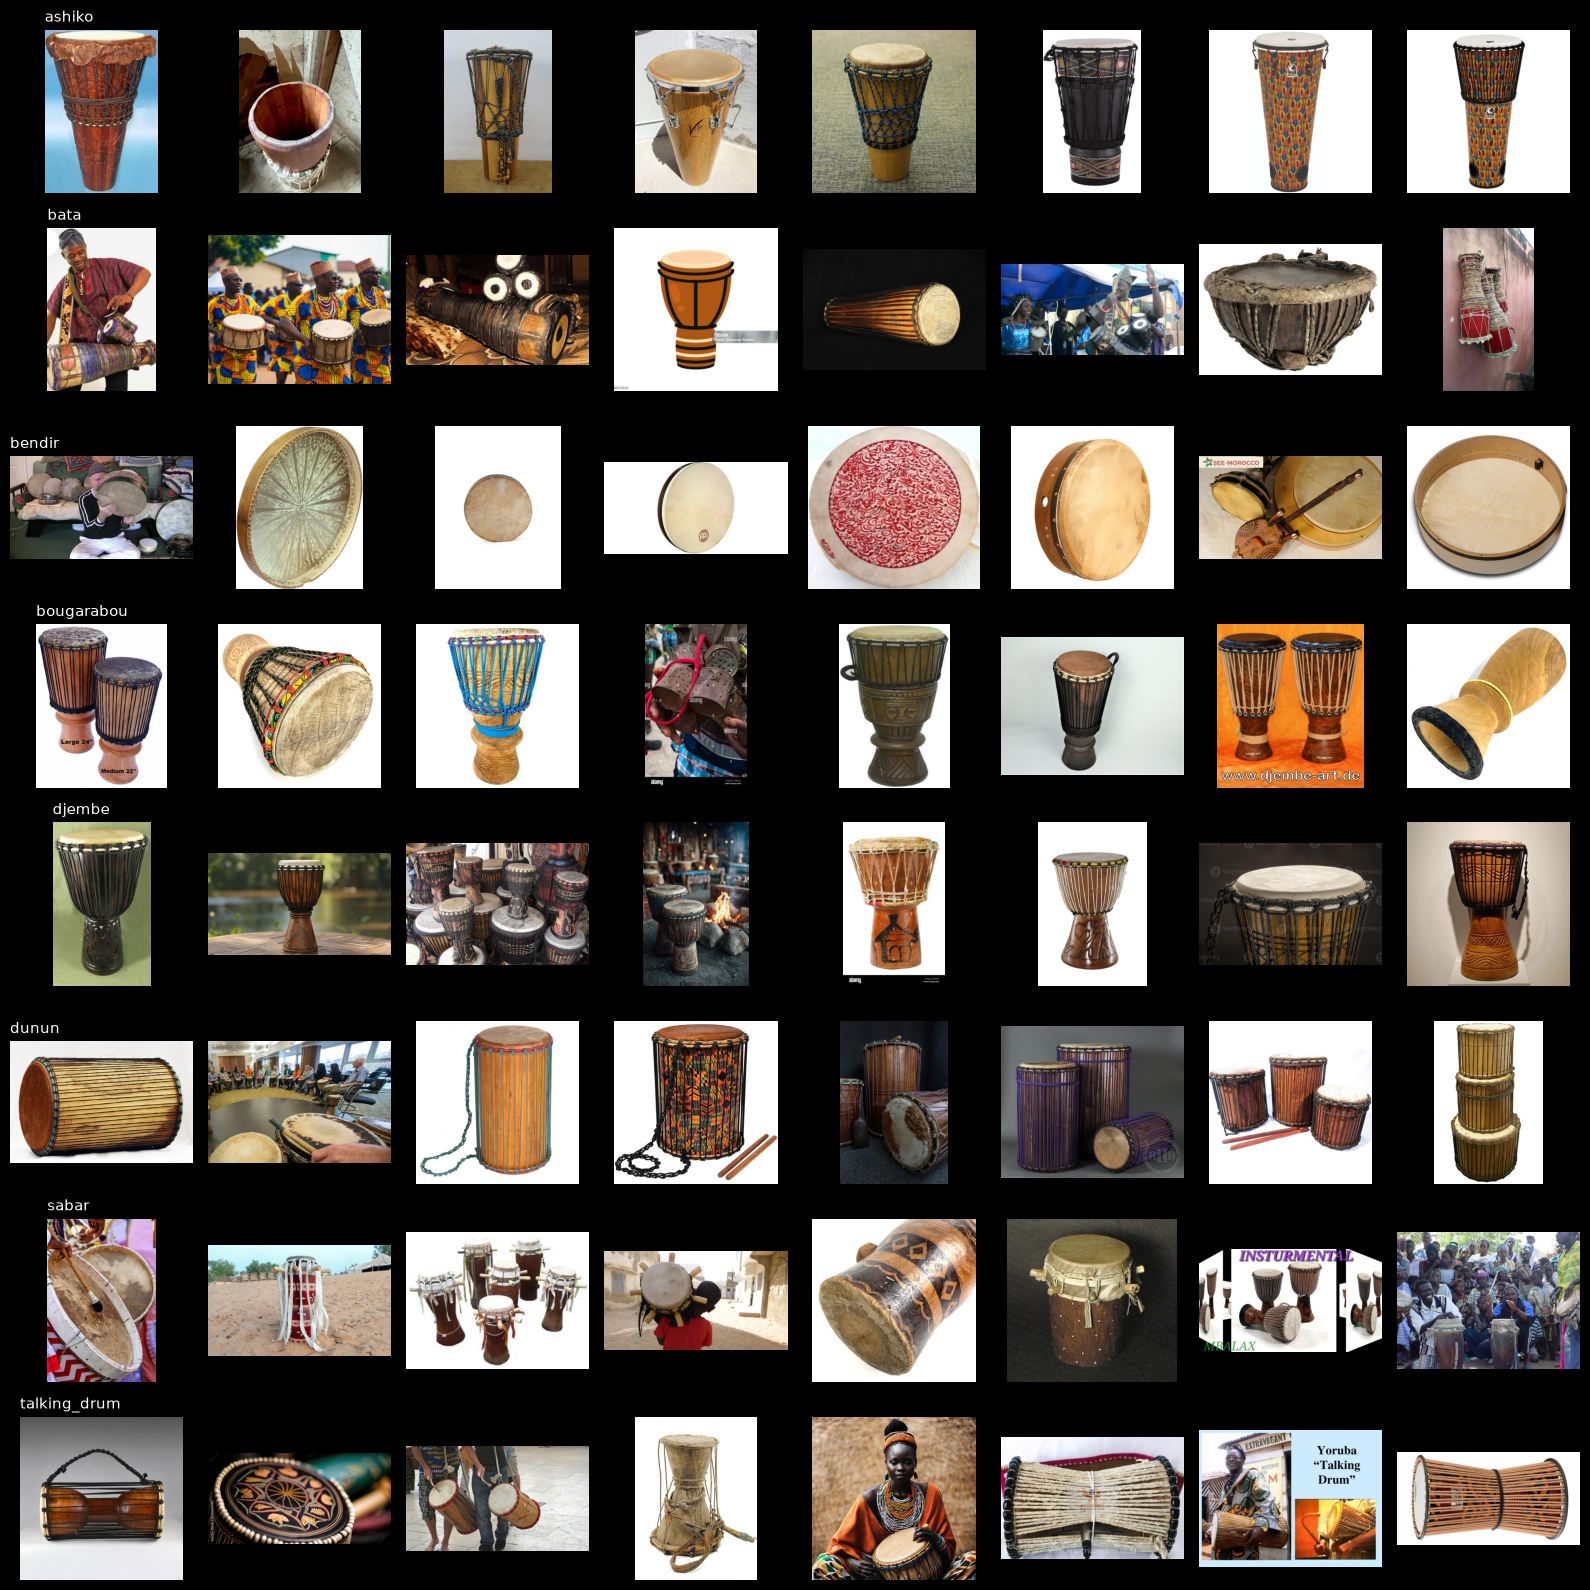

In [7]:
N_GRID = 8
fig, axes = plt.subplots(len(labels), N_GRID, figsize=(16, 2.0 * len(labels)))
for r, label in enumerate(labels):
    picks = kept_df[kept_df['label'] == label].sample(n=N_GRID, random_state=SEED)
    for c, (_, row) in enumerate(picks.iterrows()):
        axes[r, c].imshow(Image.open(row['path']))
        axes[r, c].axis('off')
        if c == 0:
            axes[r, c].set_title(label, loc='left', fontsize=11)
plt.tight_layout()
plt.show()

The grid shows that most rows are recognizably one kind of drum, but not all of them. ashiko, bendir, bougarabou, djembe and dunun are mostly clean, while bata, sabar and talking_drum still contain images where the drum is not the subject (a clip-art drawing and crowds in bata, a crowd and a text graphic in sabar, a woman with a drum and a flyer in talking_drum), so we will need to look at those classes again. Within a class, the photos differ in angle (top-down, side view, close-up of the skin), in setting (white studio background versus outdoor or indoor scenes), in decoration (plain wood versus patterned cloth) and in whether the picture shows one drum or a set. ashiko, bendir, bougarabou and dunun lean toward product photos on white or plain backgrounds, while bata, sabar and talking_drum lean toward people and performances. This is a sample of only eight images per class, so these are impressions, not measurements. The pairs that already look alike are djembe and bougarabou (both goblet-shaped with a stem) and ashiko and bougarabou (both tall and tapered).

### 3.2 Dimensions and aspect ratios

Web images come in every size and shape. We report width, height and aspect ratio (width divided by height, so a tall portrait photo is below 1 and a landscape photo is above 1), and how they differ by class. The aspect ratio by class matters later: it decides how much padding each class gets when the images are made square.

In [8]:
kept_df['aspect'] = kept_df['orig_w'] / kept_df['orig_h']

dim_summary = (kept_df[['orig_w', 'orig_h', 'aspect']]
               .rename(columns={'orig_w': 'width (px)', 'orig_h': 'height (px)', 'aspect': 'aspect (w/h)'})
               .agg(['min', 'median', 'max']).T.round(2))
display(dim_summary)

by_class = (kept_df.groupby('label')[['orig_w', 'orig_h', 'aspect']].median().round(2)
            .rename(columns={'orig_w': 'median width', 'orig_h': 'median height', 'aspect': 'median aspect'}))
display(by_class)

w_ratio = kept_df['orig_w'].max() / kept_df['orig_w'].min()
verdict = 'wildly inconsistent' if w_ratio > 10 else 'moderately inconsistent' if w_ratio > 3 else 'fairly consistent'
print(f'Widths run from {kept_df["orig_w"].min()} to {kept_df["orig_w"].max()} px, a factor of {w_ratio:.0f}: {verdict}.')
print(f'{(kept_df["aspect"] < 1).mean():.0%} of images are taller than wide, {(kept_df["aspect"] > 1).mean():.0%} wider than tall.')

,min,median,max
width (px),200.0,900.0,5184.0
height (px),200.0,800.0,6720.0
aspect (w/h),0.5,1.0,2.0


,median width,median height,median aspect
label,,,
ashiko,800.0,900.0,0.87
bata,800.0,900.0,1.00
bendir,1080.0,980.0,1.00
bougarabou,736.0,720.0,1.00
djembe,970.0,997.0,1.00
dunun,1000.0,800.0,1.33
sabar,768.5,683.0,1.33
talking_drum,900.0,720.0,1.00


Widths run from 200 to 5184 px, a factor of 26: wildly inconsistent.
33% of images are taller than wide, 43% wider than tall.


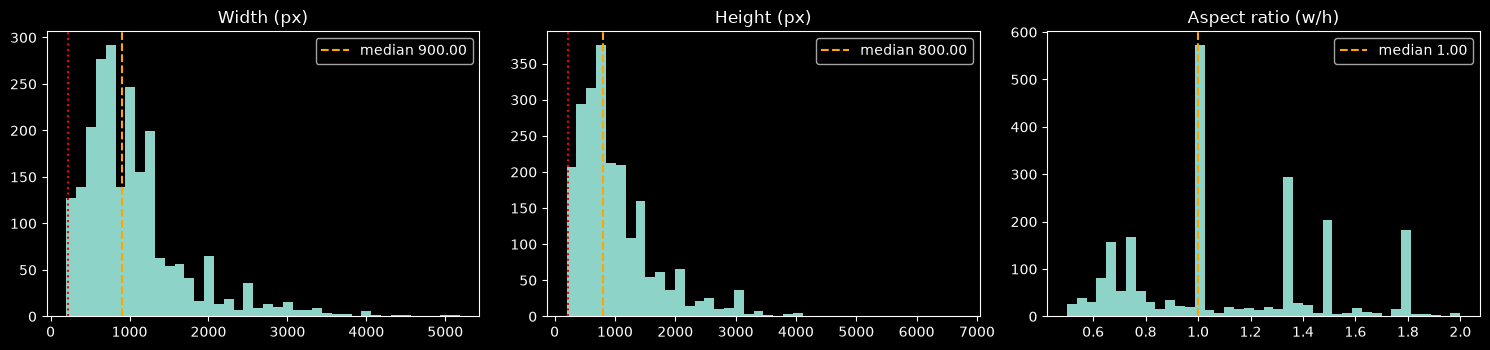

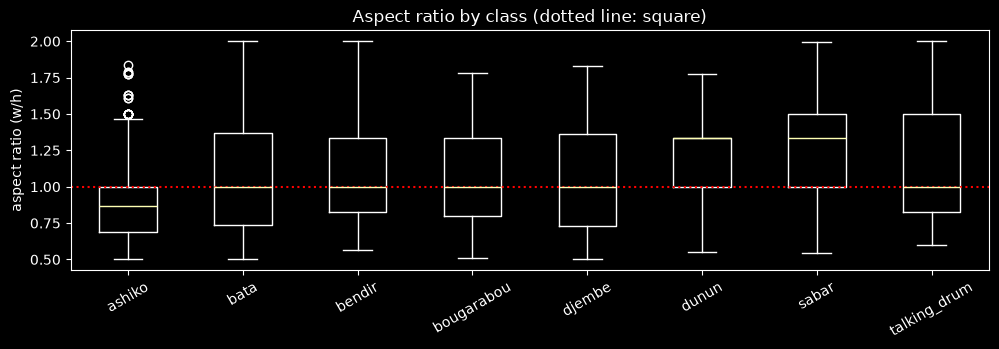

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col, title in zip(axes, ['orig_w', 'orig_h', 'aspect'], ['Width (px)', 'Height (px)', 'Aspect ratio (w/h)']):
    ax.hist(kept_df[col], bins=40)
    ax.axvline(kept_df[col].median(), color='orange', linestyle='--', label=f'median {kept_df[col].median():.2f}')
    ax.set_title(title)
    ax.legend()
axes[0].axvline(IMG_SIZE, color='red', linestyle=':')
axes[1].axvline(IMG_SIZE, color='red', linestyle=':')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.boxplot([kept_df.loc[kept_df['label'] == label, 'aspect'] for label in labels])
ax.set_xticklabels(labels, rotation=30)
ax.axhline(1.0, color='red', linestyle=':')
ax.set_ylabel('aspect ratio (w/h)')
ax.set_title('Aspect ratio by class (dotted line: square)')
plt.tight_layout()
plt.show()

The sizes are incredibly inconsistent: widths run from 200 to 5,184 px (a factor of 26) and heights from 200 to 6,720 px, with medians of 900 by 800. The shapes are less extreme, because the scraper only kept aspect ratios between 0.5 and 2.0; 33% of images are taller than wide and 43% are wider than tall. ashiko is the only class with a median aspect below 1 (0.87), which fits a tall, narrow drum photographed upright. dunun and sabar have the widest median aspect (1.33), which fits dunun photographed lying on its side and sets of drums shot side by side. The other five classes have a median of 1.00. The classes overlap a lot, so aspect ratio alone could not identify most of them, but it does separate ashiko (tall) from dunun and sabar (wide). Because of this, padding to a square will add side bars to ashiko and top and bottom bars to dunun and sabar, and we will check in Notebook 4 whether the models use that padding as a clue.

### 3.3 Class support

Counts per class after cleaning, and how uneven they are. We only **measure** the imbalance here. Fixing it (oversampling or class weights) happens in Notebook 3, and only on the training set: balancing before the split would put copies of the same image in both train and test.

,images,share
label,,
ashiko,273,0.122
bata,253,0.113
bendir,303,0.135
bougarabou,253,0.113
djembe,301,0.134
dunun,284,0.127
sabar,312,0.139
talking_drum,264,0.118


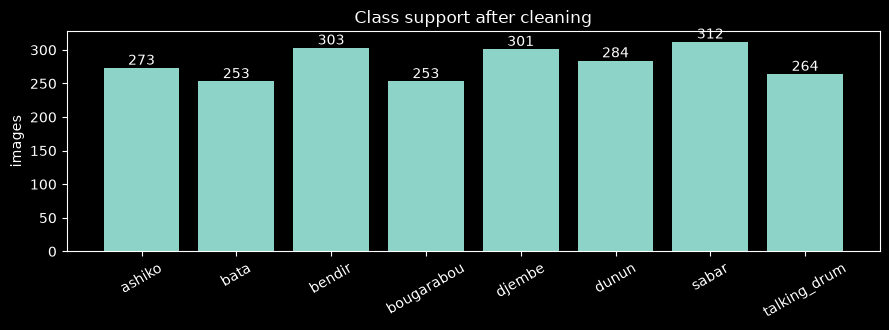

Largest class (sabar, 312) is 1.23x the smallest (bata, 253): imbalance is mild.


In [10]:
support = kept_df['label'].value_counts().reindex(labels)
display(pd.DataFrame({'images': support, 'share': (support / support.sum()).round(3)}))

fig, ax = plt.subplots(figsize=(9, 3.4))
bars = ax.bar(support.index, support.values)
ax.bar_label(bars)
ax.set_xticklabels(support.index, rotation=30)
ax.set_ylabel('images')
ax.set_title('Class support after cleaning')
plt.tight_layout()
plt.show()

ratio = support.max() / support.min()
severity = 'mild' if ratio <= 1.5 else 'moderate' if ratio <= 3 else 'severe'
print(f'Largest class ({support.idxmax()}, {support.max()}) is {ratio:.2f}x the smallest ({support.idxmin()}, {support.min()}): imbalance is {severity}.')

## 4. Preprocessing decisions

### 4.1 Color mode

Every image is converted to 3-channel RGB. A model with a 3-channel input cannot take a grayscale image (one channel) or a PNG with transparency (four channels), and a mismatch fails or, worse, silently reads the wrong channels. The scraper already converts every download to RGB before saving it, so we expect nothing to change here, but we convert anyway, for two reasons. It is cheap insurance, and the Streamlit app will receive photos uploaded by users in any mode, so the same conversion has to be part of the pipeline the app copies.

In [11]:
print(kept_df['mode'].value_counts().to_string())


def to_rgb(img):
    return img.convert('RGB')

mode
RGB    2243


### 4.2 Resize strategy

The images are all different shapes and the models need one fixed 224 × 224 size. There are three ways to get there, and each one costs something different:

- **Stretch (squash):** resize to 224 × 224 regardless of shape. Keeps every pixel of the photo but changes proportions: a tall drum is squeezed wider and a wide shot is squeezed taller.
- **Center-crop:** cut the largest centered square from the image, then resize. No distortion, but whatever lies outside the square is lost.
- **Pad:** shrink the image until its longer side is 224, then fill the rest of the square with a constant color. No distortion and nothing lost, but part of the input is empty padding.

**What each costs for drums.** Our classes are told apart mostly by *shape*: goblet, hourglass, cylinder, cone, flat frame. Stretching changes shape, so a tall `djembe` squeezed square looks closer to a `bendir` or a stubby `ashiko`. That is the worst cost for this problem. Center-cropping is just as damaging in a different way: a tall photo of an upright drum would lose its top or its base, and the base is the one place that separates a `djembe` (narrow stem) from an `ashiko` (straight cone), our predicted most-confused pair.

**Our choice: pad**, with a constant mid-gray (114, 114, 114) and the image centered. It keeps the whole drum at its true proportions. The costs we accept: tall photos use less of the 224 × 224 input for the drum (a 2:3 portrait fills only two-thirds of the width), and the padding is a risk of its own. The amount of padding is set by a photo's aspect ratio, which differs between classes (see the boxplot above). A model could learn "gray bars on the sides means `sabar`" instead of learning drums. We keep an eye on this with the per-class mean images below, and test it with saliency maps in Notebook 4.

**This choice must be copied exactly into the Streamlit app.** An uploaded photo has to go through the same steps (convert to RGB, pad to a square with the same color, resize to 224 × 224 with the same filter), or the app will misclassify images the notebook got right.

In [12]:
PAD_COLOR = (114, 114, 114)


def resize_stretch(img, size=IMG_SIZE):
    return img.resize((size, size), Image.Resampling.LANCZOS)


def resize_crop(img, size=IMG_SIZE):
    w, h = img.size
    side = min(w, h)
    left, top = (w - side) // 2, (h - side) // 2
    return img.crop((left, top, left + side, top + side)).resize((size, size), Image.Resampling.LANCZOS)


def resize_pad(img, size=IMG_SIZE, color=PAD_COLOR):
    w, h = img.size
    scale = size / max(w, h)
    new_w, new_h = max(1, round(w * scale)), max(1, round(h * scale))
    canvas = Image.new('RGB', (size, size), color)
    canvas.paste(img.resize((new_w, new_h), Image.Resampling.LANCZOS), ((size - new_w) // 2, (size - new_h) // 2))
    return canvas

The three strategies side by side on the tallest, the most square and the widest image in the dataset.

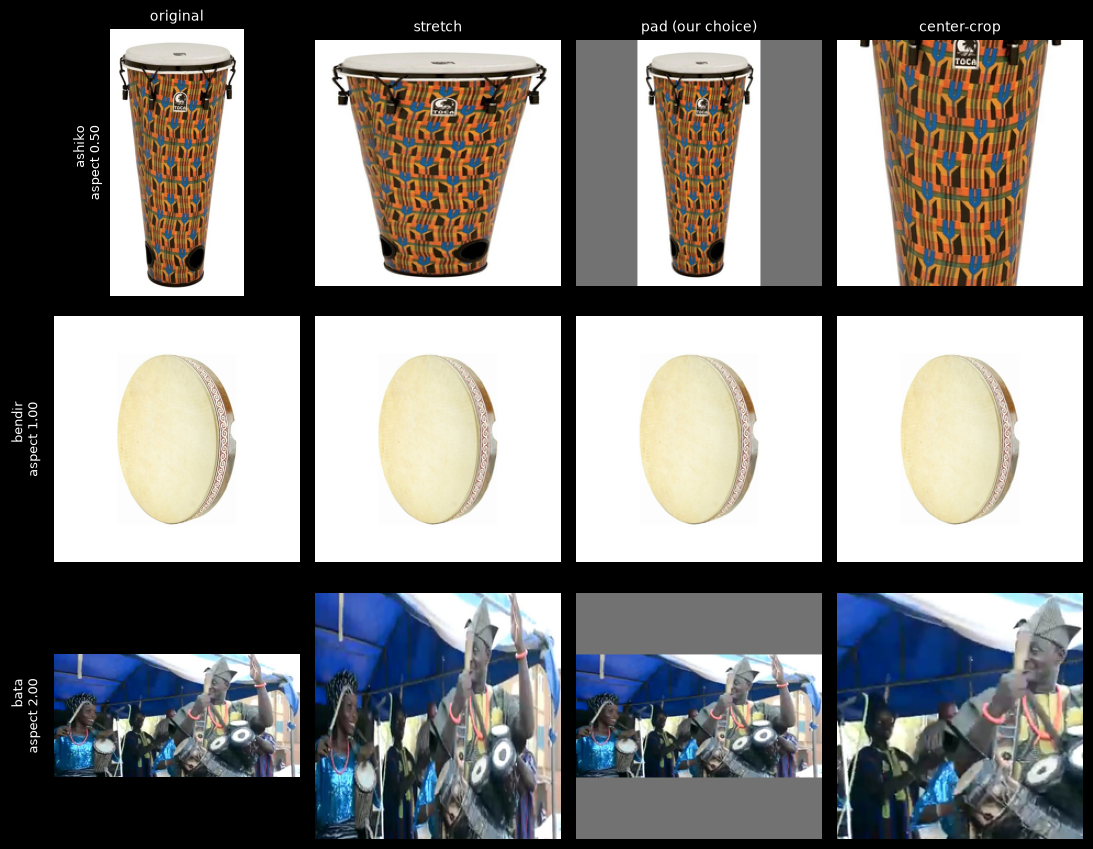

In [13]:
order = kept_df['aspect'].sort_values()
examples_ = [order.index[0], (order - 1).abs().idxmin(), order.index[-1]]

fig, axes = plt.subplots(len(examples_), 4, figsize=(11, 2.9 * len(examples_)))
for r, idx in enumerate(examples_):
    with Image.open(kept_df.at[idx, 'path']) as img:
        img = to_rgb(img)
        for ax, (title, shown) in zip(axes[r], [('original', img), ('stretch', resize_stretch(img)),
                                               ('pad (our choice)', resize_pad(img)), ('center-crop', resize_crop(img))]):
            ax.imshow(shown)
            ax.set_title(title if r == 0 else '', fontsize=10)
            ax.axis('off')
    axes[r, 0].text(-0.05, 0.5, f'{kept_df.at[idx, "label"]}\naspect {kept_df.at[idx, "aspect"]:.2f}',
                    transform=axes[r, 0].transAxes, rotation=90, va='center', ha='right', fontsize=9)
plt.tight_layout()
plt.show()

### 4.3 Applying the preprocessing

Every kept image goes through `to_rgb` and then `resize_pad`, and is stored as raw 0–255 pixel values (`uint8`) with **no** model-specific scaling. Each Keras application expects its input scaled differently and ships its own `preprocess_input`; applying one here would bake a single model's scaling into data that three or more different models will read. Notebook 3 applies the right one for each model.

In [14]:
X = np.empty((len(kept_df), IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8)
for i, path in enumerate(kept_df['path']):
    with Image.open(path) as img:
        X[i] = np.asarray(resize_pad(to_rgb(img)))

print(f'{X.shape[0]} images -> array of shape {X.shape}, dtype {X.dtype}, values {X.min()} to {X.max()}')

2243 images -> array of shape (2243, 224, 224, 3), dtype uint8, values 0 to 255


### 4.4 Per-class mean image

The average of every image in a class, after resizing. If a class's mean image shows a recognizable shape, or a consistent colored border, that is a shortcut waiting to happen, and Notebook 4 checks whether the saliency maps land on it.

The top row is the plain mean. The bottom row shows how each class's mean *differs from the mean of all classes*, stretched so the differences are visible: a pale or dark region means that area is brighter or darker in that class than in the dataset as a whole. With padding, expect the gray padding to show up here.

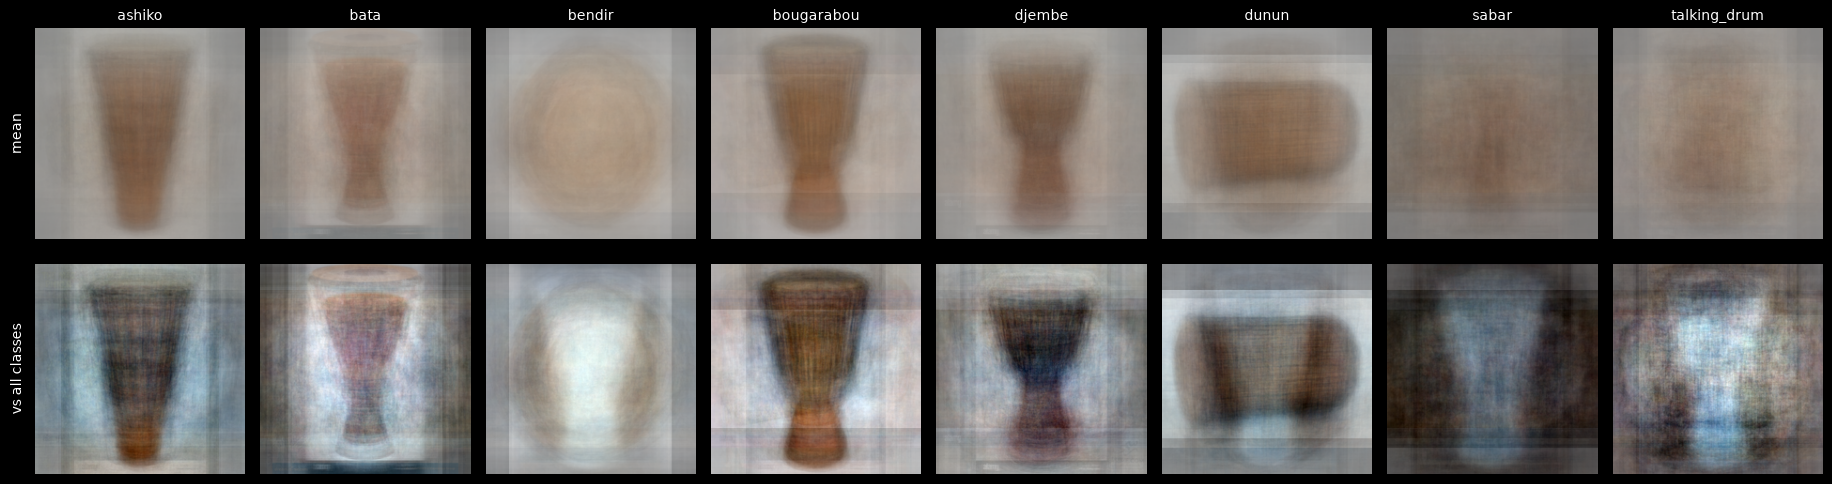

In [15]:
class_means = {label: X[(kept_df['label'] == label).to_numpy()].mean(axis=0) for label in labels}
overall_mean = X.mean(axis=0)

fig, axes = plt.subplots(2, len(labels), figsize=(2.3 * len(labels), 5.2))
for c, label in enumerate(labels):
    axes[0, c].imshow(class_means[label].astype(np.uint8))
    axes[0, c].set_title(label, fontsize=10)
    diff = class_means[label] - overall_mean
    axes[1, c].imshow(np.clip(0.5 + diff / (2 * np.abs(diff).max()), 0, 1))
    axes[0, c].axis('off')
    axes[1, c].axis('off')
axes[0, 0].text(-0.05, 0.5, 'mean', transform=axes[0, 0].transAxes, rotation=90, va='center', ha='right')
axes[1, 0].text(-0.05, 0.5, 'vs all classes', transform=axes[1, 0].transAxes, rotation=90, va='center', ha='right')
plt.tight_layout()
plt.show()

Five classes show a shape we can recognize in the mean image: ashiko is a tall tapered body, bendir a round frame, bougarabou and djembe a goblet with a narrow stem, and dunun a wide rounded rectangle that matches a cylinder lying on its side. bata shows a faint hourglass, but it is blurrier and may be partly from the clip-art drawings. sabar and talking_drum show no clear shape, because their photos vary too much in pose and many are people or performances. Gray padding is visible, and it differs by class: ashiko has gray bars at the sides, while dunun has them at the top and bottom, which matches the aspect ratios in section 3.2. The bottom row shows light-blue areas in the center of sabar and talking_drum (where their drum is less often than in other classes) and a dark band near the bottom of bata, which could be stock-photo watermarks or bars; we cannot tell from this plot alone. In Notebook 4 we will check whether the models use padding, backgrounds or watermarks instead of the drum, especially for dunun, bata and the sabar and talking_drum classes.

## 5. Split and export

### 5.1 Label-to-index mapping

Notebooks 3 and 4 and the app all need the identical mapping from class name to number, and a mismatch silently permutes the class names without raising an error. We build it from the class names in alphabetical order, so it is the same every time it is built from the same classes, and save it once so the other notebooks load it instead of rebuilding it.

### 5.2 The 80/20 split

We split the cleaned images 80% train and 20% test, **stratified by class** so each class keeps the same proportion in both sets, with `random_state=42` so the split is reproducible. The stratification matters most for the smallest classes: a random split could give a class with 200 images a test set noticeably smaller or larger than 20%.

The split happens **before** any balancing or augmentation. Both are done in Notebook 3, on the training set only. Doing either first would copy or synthesize training images and then let those copies fall into the test set, and the test accuracy would measure memory, not generalization. The test set stays at its natural class distribution, because that is what we want to measure.

In [16]:
label_to_index = {label: i for i, label in enumerate(sorted(labels))}
y = kept_df['label'].map(label_to_index).to_numpy()

idx_train, idx_test = train_test_split(np.arange(len(kept_df)), test_size=0.2, stratify=y, random_state=SEED)
X_train, y_train = X[idx_train], y[idx_train]
X_test, y_test = X[idx_test], y[idx_test]

split_counts = pd.DataFrame({'train': pd.Series(y_train).map({v: k for k, v in label_to_index.items()}).value_counts(),
                             'test': pd.Series(y_test).map({v: k for k, v in label_to_index.items()}).value_counts()}).reindex(labels)
split_counts['test share'] = (split_counts['test'] / (split_counts['train'] + split_counts['test'])).round(3)
split_counts.loc['TOTAL'] = [split_counts['train'].sum(), split_counts['test'].sum(),
                             round(split_counts['test'].sum() / (split_counts['train'].sum() + split_counts['test'].sum()), 3)]
split_counts

,train,test,test share
ashiko,218.0,55.0,0.201
bata,202.0,51.0,0.202
bendir,242.0,61.0,0.201
bougarabou,203.0,50.0,0.198
djembe,241.0,60.0,0.199
dunun,227.0,57.0,0.201
sabar,250.0,62.0,0.199
talking_drum,211.0,53.0,0.201
TOTAL,1794.0,449.0,0.200


### 5.3 Export

Everything below goes into a local folder outside the repo, because the arrays are made of the scraped images and must not be committed.

| File | Contents |
|---|---|
| `X_train.npy`, `X_test.npy` | Images, shape `(n, 224, 224, 3)`, `uint8`, raw 0–255 |
| `y_train.npy`, `y_test.npy` | Class indices, in the same order as the images |
| `label_to_index.json` | Class name to index mapping |
| `split.csv` | For every row of the arrays: which split, its position, filename and label, so a test image can be traced back to its file |
| `preprocessing.json` | Color mode, resize strategy, pad color, size and filter, so the app can copy the pipeline exactly |

`.npy` arrays load in one call and keep the exact pixel values, which is what Notebook 3 needs.

In [17]:
np.save(OUT_DIR / 'X_train.npy', X_train)
np.save(OUT_DIR / 'y_train.npy', y_train)
np.save(OUT_DIR / 'X_test.npy', X_test)
np.save(OUT_DIR / 'y_test.npy', y_test)

(OUT_DIR / 'label_to_index.json').write_text(json.dumps(label_to_index, indent=2))

split_table = pd.concat([
    pd.DataFrame({'split': 'train', 'position': np.arange(len(idx_train)),
                  'filename': kept_df.loc[idx_train, 'filename'].to_numpy(), 'label': kept_df.loc[idx_train, 'label'].to_numpy()}),
    pd.DataFrame({'split': 'test', 'position': np.arange(len(idx_test)),
                  'filename': kept_df.loc[idx_test, 'filename'].to_numpy(), 'label': kept_df.loc[idx_test, 'label'].to_numpy()}),
], ignore_index=True)
split_table.to_csv(OUT_DIR / 'split.csv', index=False)

(OUT_DIR / 'preprocessing.json').write_text(json.dumps({
    'color_mode': 'RGB', 'resize_strategy': 'pad', 'pad_color': list(PAD_COLOR), 'img_size': IMG_SIZE,
    'resample_filter': 'LANCZOS', 'dtype': 'uint8', 'value_range': [0, 255],
    'split': {'test_size': 0.2, 'stratified': True, 'random_state': SEED},
}, indent=2))

print(f'Saved to {OUT_DIR}')
for name in ['X_train.npy', 'X_test.npy', 'y_train.npy', 'y_test.npy', 'label_to_index.json', 'split.csv', 'preprocessing.json']:
    print(f'  {name:<22} {(OUT_DIR / name).stat().st_size / 1e6:8.1f} MB')

Saved to /Users/mikeflanders/MSDS565_data/P2_processed
  X_train.npy               270.0 MB
  X_test.npy                 67.6 MB
  y_train.npy                 0.0 MB
  y_test.npy                  0.0 MB
  label_to_index.json         0.0 MB
  split.csv                   0.1 MB
  preprocessing.json          0.0 MB


### 5.4 Updating the manifest

Notebook 1's manifest is the record of what we scraped. We add to it rather than replace it: `kept` marks which images survived cleaning, `drop_reason` says why each of the others did not, and `split` says which side of the split every kept image landed on. Nothing in the original columns changes. This file goes in the repo and is the only record of the dataset that does.

In [18]:
split_of = {(label, name): split for label, name, split in zip(split_table['label'], split_table['filename'], split_table['split'])}
manifest['split'] = [split_of.get((label, name)) for label, name in zip(manifest['label'], manifest['filename'])]

helper_columns = ['path', 'on_disk', 'orig_w', 'orig_h', 'mode']     # working columns, not part of the record
updated = manifest.drop(columns=helper_columns)
updated.to_csv(MANIFEST_PATH, index=False)

print(f'{len(updated)} rows written to {MANIFEST_PATH}; columns: {list(updated.columns)}')
pd.crosstab(updated['kept'], updated['split'].fillna('(not in dataset)'))

2782 rows written to ../data/P2_manifest.csv; columns: ['filename', 'label', 'source_url', 'query', 'readable', 'image_url', 'title', 'width', 'height', 'drop_reason', 'kept', 'split']


split,(not in dataset),test,train
kept,,,
False,539,0,0
True,0,449,1794


### 5.5 Final checks

A last look at what was actually written, reading it back from disk the way Notebook 3 will: shapes and types, the value range, the label mapping, and a check that no identical image sits in both the train and the test set.

In [19]:
X_train_back = np.load(OUT_DIR / 'X_train.npy')
X_test_back = np.load(OUT_DIR / 'X_test.npy')
y_train_back = np.load(OUT_DIR / 'y_train.npy')
y_test_back = np.load(OUT_DIR / 'y_test.npy')
mapping_back = json.loads((OUT_DIR / 'label_to_index.json').read_text())

assert X_train_back.dtype == X_test_back.dtype == np.uint8
assert X_train_back.shape[1:] == X_test_back.shape[1:] == (IMG_SIZE, IMG_SIZE, 3)
assert len(X_train_back) == len(y_train_back) and len(X_test_back) == len(y_test_back)
assert mapping_back == label_to_index and sorted(mapping_back.values()) == list(range(len(labels)))
assert set(y_train_back) == set(y_test_back) == set(mapping_back.values())     # every class is in both splits

# Independent of the audit in 2.2: byte-for-byte identical images across the split
train_hashes = {hashlib.md5(a.tobytes()).hexdigest() for a in X_train_back}
test_hashes = {hashlib.md5(a.tobytes()).hexdigest() for a in X_test_back}
leaked = train_hashes & test_hashes
assert not leaked, f'{len(leaked)} identical images appear in both train and test'

print(f'train {X_train_back.shape}, test {X_test_back.shape}, dtype {X_train_back.dtype}, '
      f'values {int(X_train_back.min())} to {int(X_train_back.max())}')
print('label_to_index:', mapping_back)
print('No identical images shared between train and test')

train (1794, 224, 224, 3), test (449, 224, 224, 3), dtype uint8, values 0 to 255
label_to_index: {'ashiko': 0, 'bata': 1, 'bendir': 2, 'bougarabou': 3, 'djembe': 4, 'dunun': 5, 'sabar': 6, 'talking_drum': 7}
No identical images shared between train and test


## Review

This notebook turned the scraper's folders into a model-ready dataset:

1. **Loading** read the manifest and the folders separately, so the gap between them is the cleaning
2. **The cleaning summary** gave every image exactly one fate, audited for duplicates (including the same image under two classes), and confirmed every class clears 200 images
3. **The EDA** showed what the images look like, how inconsistent their sizes and shapes are, how the classes are balanced, and what each class's average image looks like
4. **Preprocessing** converted everything to RGB and padded each image to a 224 × 224 square, keeping each drum's true proportions, and stored raw 0–255 pixels so each model can apply its own scaling later
5. **The split** was stratified 80/20 with `random_state=42`, done before any balancing or augmentation
6. **The export** wrote the arrays, the label-to-index mapping, the split table and the preprocessing settings to a local folder, and added `kept`, `drop_reason` and `split` to the manifest

**Next:** `P2_Images-3_TransferLearning.ipynb` balances and augments the training set, embeds it with three or more pretrained Keras applications of different sizes, and trains a linear probe on each.